This notebook cleans and vectorizes airline tweets (positive/negative only) with TF-IDF and trains a Multinomial Naive Bayes sentiment classifier. It reaches 83.07% accuracy and 100% precision on the test set, but only 17.34% recall (F1-score 0.2955), showing the independence assumption struggles more on tweets than on spam SMS.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

In [2]:
#Task1 (continued)

tweets_df = pd.read_csv("/kaggle/input/twitter-airline-sentiment/Tweets.csv")

print("Tweets shape (before dropping neutral):", tweets_df.shape)

tweets_df = tweets_df[tweets_df["airline_sentiment"].isin(["positive", "negative"])].copy()

print("Tweets shape (after dropping neutral):", tweets_df.shape)
display(tweets_df[["airline_sentiment", "text"]].head())

print("\nClass counts:")
print(tweets_df["airline_sentiment"].value_counts())
print("\nClass percentages:")
print(tweets_df["airline_sentiment"].value_counts(normalize=True) * 100)

Tweets shape (before dropping neutral): (14640, 15)
Tweets shape (after dropping neutral): (11541, 15)


,airline_sentiment,text
1,positive,@VirginAmerica plus you've added commercials t...
3,negative,@VirginAmerica it's really aggressive to blast...
4,negative,@VirginAmerica and it's a really big bad thing...
5,negative,@VirginAmerica seriously would pay $30 a fligh...
6,positive,"@VirginAmerica yes, nearly every time I fly VX..."



Class counts:
airline_sentiment
negative    9178
positive    2363
Name: count, dtype: int64

Class percentages:
airline_sentiment
negative    79.525171
positive    20.474829
Name: proportion, dtype: float64


In [3]:
#Task11

def clean_tweet(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"[^a-z\s]", "", text)
    return text

tweets_df["text_clean"] = tweets_df["text"].apply(clean_tweet)

y_sentiment = tweets_df["airline_sentiment"].map({"negative": 0, "positive": 1})

X_train_tweet, X_test_tweet, y_train_sentiment, y_test_sentiment = train_test_split(
    tweets_df["text_clean"], y_sentiment,
    test_size=0.20,
    random_state=42,
    stratify=y_sentiment
)

tweet_vectorizer = TfidfVectorizer()
X_train_tweet_vec = tweet_vectorizer.fit_transform(X_train_tweet)
X_test_tweet_vec = tweet_vectorizer.transform(X_test_tweet)

print("Vocabulary size:", len(tweet_vectorizer.get_feature_names_out()))
print("X_train_tweet_vec shape:", X_train_tweet_vec.shape)
print("X_test_tweet_vec shape:", X_test_tweet_vec.shape)

Vocabulary size: 9656
X_train_tweet_vec shape: (9232, 9656)
X_test_tweet_vec shape: (2309, 9656)


,Metric,Naive Bayes
0,Accuracy,0.830663
1,Precision,1.000000
2,Recall,0.173362
3,F1-Score,0.295495


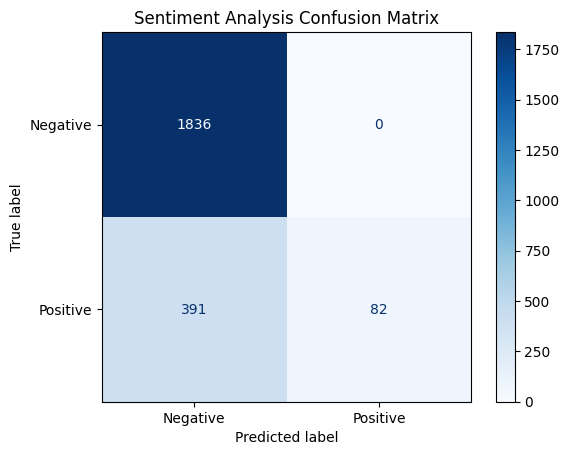

In [4]:
#Task13

nb_sentiment = MultinomialNB()
nb_sentiment.fit(X_train_tweet_vec, y_train_sentiment)

sentiment_test_pred = nb_sentiment.predict(X_test_tweet_vec)

sentiment_accuracy = accuracy_score(y_test_sentiment, sentiment_test_pred)
sentiment_precision = precision_score(y_test_sentiment, sentiment_test_pred)
sentiment_recall = recall_score(y_test_sentiment, sentiment_test_pred)
sentiment_f1 = f1_score(y_test_sentiment, sentiment_test_pred)

sentiment_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Naive Bayes": [sentiment_accuracy, sentiment_precision, sentiment_recall, sentiment_f1]
})

display(sentiment_results)

ConfusionMatrixDisplay.from_predictions(y_test_sentiment, sentiment_test_pred, display_labels=["Negative", "Positive"], cmap="Blues")
plt.title("Sentiment Analysis Confusion Matrix")
plt.show()